In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
import seaborn as sns
import os
os.chdir("E:/Vishal_Adesh/CDAC/Machine Learning/Datasets")
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [3]:
df = pd.read_csv("rfm_data_customer.csv",index_col=0)
df.head()

,revenue,most_recent_visit,number_of_orders,recency_days
customer_id,,,,
22086,777,2006-05-14,9,232
2290,1555,2006-09-08,16,115
26377,336,2006-11-19,5,43
24650,1189,2006-10-29,12,64
12883,1229,2006-12-09,12,23


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39999 entries, 22086 to 19184
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   revenue           39999 non-null  int64
 1   number_of_orders  39999 non-null  int64
 2   recency_days      39999 non-null  int64
dtypes: int64(3)
memory usage: 2.2 MB


In [6]:
df.drop("most_recent_visit",axis=1, inplace=True)

In [7]:
scaler = StandardScaler().set_output(transform='pandas')
scl_df = scaler.fit_transform(df)

In [9]:
scl_df.head()

,revenue,number_of_orders,recency_days
customer_id,,,
22086,-0.464600,-0.265676,0.385878
2290,1.774110,1.972752,-0.506581
26377,-1.733586,-1.544778,-1.055787
24650,0.720938,0.693650,-0.895602
12883,0.836039,0.693650,-1.208344


In [21]:
ks = np.arange(1,21)
wss = []
for k in ks:
    km = KMeans(n_clusters=k,random_state=26)
    km.fit(scl_df)
    wss.append([k,km.inertia_])
df_wss = pd.DataFrame(wss,columns=["K","wss"])
df_wss.sort_values("wss",ascending=True)

,K,wss
19,20,12770.006811
18,19,13257.088826
17,18,13781.487861
16,17,14203.017310
15,16,14739.184809
14,15,15294.772670
13,14,16005.765628
12,13,16787.213910
11,12,17597.972440
10,11,18598.650978


In [24]:
ks = np.arange(2,21)
ss = []
for k in ks:
    km = KMeans(n_clusters=k,random_state=26)
    km.fit(scl_df)
    score = silhouette_score(scl_df,km.labels_)
    ss.append([k,score])
df_ss = pd.DataFrame(wss,columns=["K","Silhouette_Score"])
df_ss.sort_values("Silhouette_Score",ascending=True)

,K,Silhouette_Score
19,20,12770.006811
18,19,13257.088826
17,18,13781.487861
16,17,14203.017310
15,16,14739.184809
14,15,15294.772670
13,14,16005.765628
12,13,16787.213910
11,12,17597.972440
10,11,18598.650978


In [26]:
df_ss.sort_values("Silhouette_Score",ascending=False)

,K,Silhouette_Score
0,1,119997.000000
1,2,68990.000387
2,3,47719.556968
3,4,37407.431444
4,5,31818.174608
5,6,27607.036648
6,7,25416.795687
7,8,22972.521209
8,9,21028.736777
9,10,19633.782158


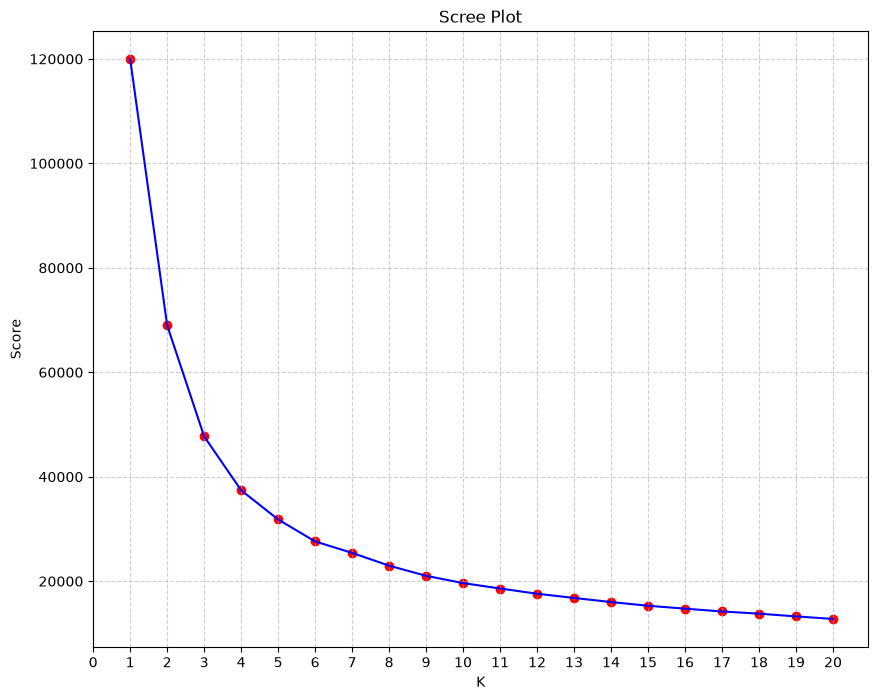

In [25]:
plt.figure(figsize=(10,8))
plt.scatter(df_wss["K"],df_wss["wss"],c='red')
plt.plot(df_wss["K"],df_wss["wss"],c='blue')
plt.title("Scree Plot")
plt.xticks(range(0, 21))
plt.xlabel("K")
plt.ylabel("Score")
plt.grid(True,linestyle='--',alpha=0.6)
plt.show()

Recommended optimal K: 4


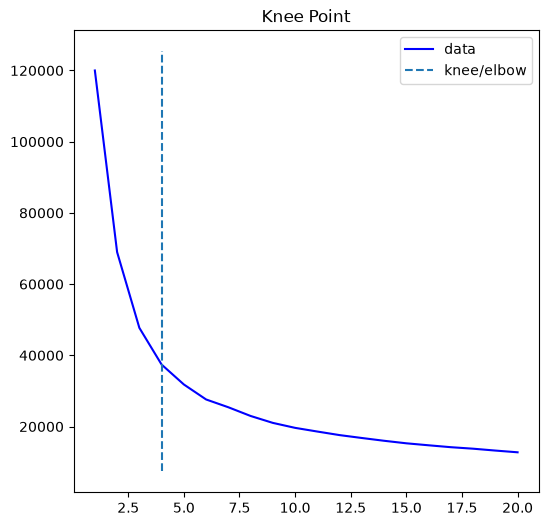

In [27]:
from kneed import KneeLocator
# Automatically find and print the optimal elbow point
kl = KneeLocator(
    df_wss["K"], 
    df_wss["wss"], 
    curve="convex", 
    direction="decreasing"
)

print(f"Recommended optimal K: {kl.elbow}")

# Optional: Plot the knee detection curve
kl.plot_knee()
plt.show()

## Analyzing with best k : 4

In [ ]:
km = KMeans(n_clusters=4,random_state=26)
km.fit(scl_df)
df_copy = df.copy()
df_copy["Clusters"] = km.labels_
df_copy.gr